### 1. Install and Import Required Libraries
First, let's make sure we have `mlxtend` and other standard libraries imported.

In [1]:
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules
import matplotlib.pyplot as plt
import seaborn as sns

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 2. Prepare the Dataset
Since you mentioned a 4-column dataset, let's construct a synthetic one representing a typical retail store dataset. The 4 columns are:
1. `Transaction_ID` (to group items bought together)
2. `Item_Description` (the name of the product)
3. `Quantity` (how many items bought)
4. `Price` (price per item)

In [2]:
# Simulating a 4-column transaction dataset
data = {
    'Transaction_ID': [1, 1, 1, 2, 2, 3, 3, 3, 4, 4, 5, 5, 5, 6, 6, 7, 7, 8, 8, 8],
    'Item_Description': ['Bread', 'Milk', 'Butter', 'Bread', 'Butter', 'Milk', 'Diaper', 'Beer', 'Bread', 'Milk', 'Bread', 'Milk', 'Diaper', 'Milk', 'Beer', 'Bread', 'Diaper', 'Milk', 'Diaper', 'Beer'],
    'Quantity': [1, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1],
    'Price': [2.5, 1.5, 3.0, 2.5, 3.0, 1.5, 15.0, 4.0, 2.5, 1.5, 2.5, 1.5, 15.0, 1.5, 4.0, 2.5, 15.0, 1.5, 15.0, 4.0]
}

df = pd.DataFrame(data)
print("Original 4-column Dataset:")
display(df.head(10))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Original 4-column Dataset:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Transaction_ID,Item_Description,Quantity,Price
0,1,Bread,1,2.5
1,1,Milk,2,1.5
2,1,Butter,1,3.0
3,2,Bread,1,2.5
4,2,Butter,1,3.0
5,3,Milk,1,1.5
6,3,Diaper,1,15.0
7,3,Beer,1,4.0
8,4,Bread,2,2.5
9,4,Milk,1,1.5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### 3. One-Hot Encoding the Transactions
To perform market basket analysis, we need to transform our transactional format into a matrix where columns are the individual products, and rows correspond to unique `Transaction_ID` values. Each cell indicates whether the item was present in that transaction.

In [3]:
# Pivot the table to get Transaction_ID as index and Item_Description as columns
basket = (df.groupby(['Transaction_ID', 'Item_Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('Transaction_ID'))

# Convert quantities to binary (True/False or 1/0) values representing present/not present
def encode_units(x):
    if x <= 0:
        return False
    return True

basket_sets = basket.map(encode_units)
print("One-Hot Encoded Transaction Matrix:")
display(basket_sets.head())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

One-Hot Encoded Transaction Matrix:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Item_Description,Beer,Bread,Butter,Diaper,Milk
Transaction_ID,,,,,
1,False,True,True,False,True
2,False,True,True,False,False
3,True,False,False,True,True
4,False,True,False,False,True
5,False,True,False,True,True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### 4. Apply Apriori Algorithm to Find Frequent Itemsets
We will find items that are bought together frequently using a minimum support threshold (e.g., 20%).

In [4]:
frequent_itemsets = apriori(basket_sets, min_support=0.2, use_colnames=True)
# Sort frequent itemsets by support descending
frequent_itemsets = frequent_itemsets.sort_values(by='support', ascending=False)
print("Frequent Itemsets:")
display(frequent_itemsets)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Frequent Itemsets:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
4,0.750,(Milk)
1,0.625,(Bread)
3,0.500,(Diaper)
0,0.375,(Beer)
10,0.375,"(Diaper, Milk)"
6,0.375,"(Beer, Milk)"
9,0.375,"(Bread, Milk)"
2,0.250,(Butter)
7,0.250,"(Butter, Bread)"
5,0.250,"(Beer, Diaper)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### 5. Generate Association Rules
Now, we derive the association rules from the frequent itemsets based on metrics like lift or confidence.

In [5]:
# Generate rules using association_rules
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Sort the rules by confidence descending
rules = rules.sort_values(by='confidence', ascending=False)
print("Association Rules:")
display(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Association Rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
4,(Butter),(Bread),0.250,1.000000,1.600000
2,(Beer),(Milk),0.375,1.000000,1.333333
8,"(Beer, Diaper)",(Milk),0.250,1.000000,1.333333
0,(Diaper),(Milk),0.375,0.750000,1.000000
6,(Beer),(Diaper),0.250,0.666667,1.333333
9,"(Beer, Milk)",(Diaper),0.250,0.666667,1.333333
11,(Beer),"(Diaper, Milk)",0.250,0.666667,1.777778
10,"(Diaper, Milk)",(Beer),0.250,0.666667,1.777778
1,(Milk),(Diaper),0.375,0.500000,1.000000
3,(Milk),(Beer),0.375,0.500000,1.333333


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### 6. Rule Evaluation and Visualization
Let's visualize the generated rules using a scatter plot mapping **Support** vs **Confidence**, with the point sizes and colors mapped to **Lift**. This helps quickly identify the most significant rules.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

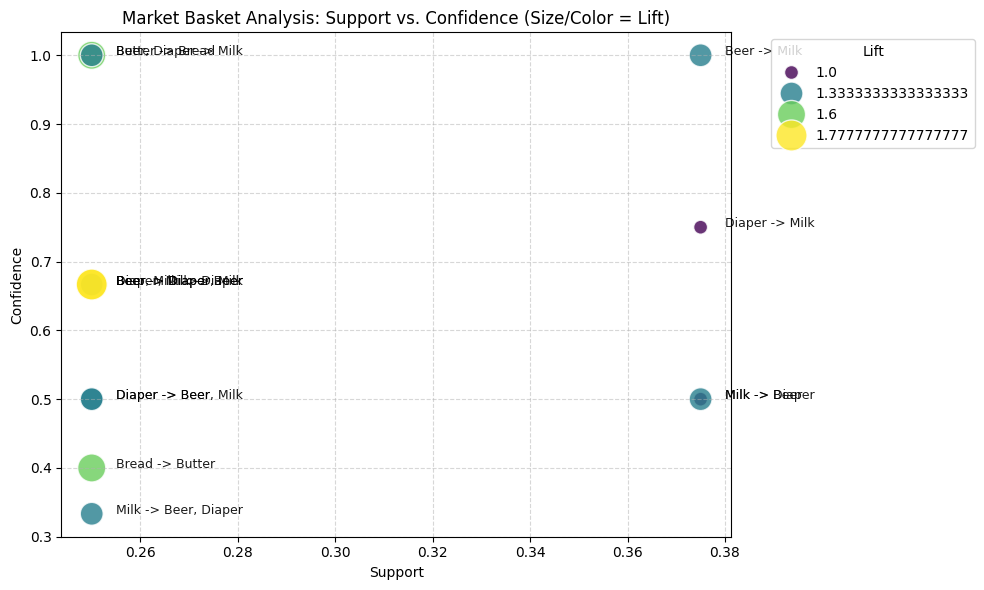

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [6]:
# Format rule labels for the plot
rules['rule_label'] = rules['antecedents'].apply(lambda x: ', '.join(list(x))) + ' -> ' + rules['consequents'].apply(lambda x: ', '.join(list(x)))

# Create a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rules,
    x='support',
    y='confidence',
    size='lift',
    hue='lift',
    palette='viridis',
    sizes=(100, 500),
    alpha=0.8
)

# Annotate the rules directly on the plot
for idx, row in rules.iterrows():
    plt.text(row['support'] + 0.005, row['confidence'], row['rule_label'], fontsize=9, alpha=0.9)

plt.title('Market Basket Analysis: Support vs. Confidence (Size/Color = Lift)')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Lift')
plt.tight_layout()
plt.show()

### 8. Advanced Visualizations: Co-occurrence Heatmap & Association Network

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

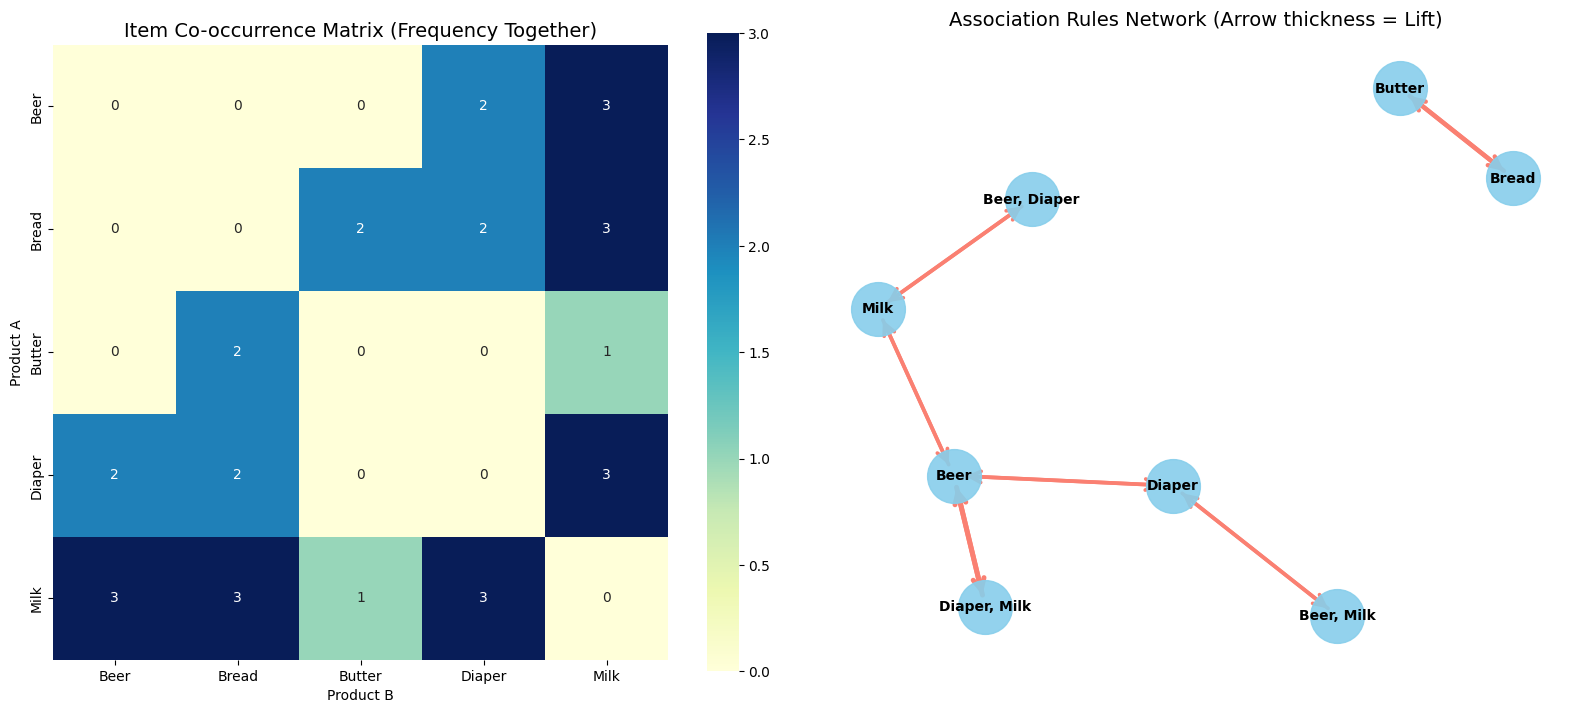

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [7]:
import networkx as nx

# 1. Co-occurrence Matrix Heatmap
# Calculate the co-occurrence matrix by multiplying the transpose of the transaction matrix with itself
co_occurrence = basket_sets.T.astype(int).dot(basket_sets.astype(int))

# Fill diagonal with 0s to focus on co-purchases rather than individual item counts
np.fill_diagonal(co_occurrence.values, 0)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot Heatmap
sns.heatmap(
    co_occurrence,
    annot=True,
    cmap='YlGnBu',
    cbar=True,
    square=True,
    ax=axes[0]
)
axes[0].set_title('Item Co-occurrence Matrix (Frequency Together)', fontsize=14)
axes[0].set_xlabel('Product B')
axes[0].set_ylabel('Product A')

# 2. Association Rules Network Graph
G = nx.DiGraph()

# Add nodes and edges from the rules with lift >= 1.2
for idx, row in rules[rules['lift'] >= 1.2].iterrows():
    ant = ', '.join(list(row['antecedents']))
    cons = ', '.join(list(row['consequents']))
    # We add edge weighted by lift
    G.add_edge(ant, cons, weight=row['lift'], confidence=row['confidence'])

pos = nx.spring_layout(G, k=1.0, seed=42)

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_size=1500, node_color='skyblue', alpha=0.9, ax=axes[1])
# Draw labels
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold', ax=axes[1])
# Draw edges with width depending on lift
edges = G.edges(data=True)
weights = [edge[2]['weight'] * 2 for edge in edges]
nx.draw_networkx_edges(
    G, pos,
    width=weights,
    edge_color='salmon',
    arrowstyle='->',
    arrowsize=20,
    ax=axes[1]
)

axes[1].set_title('Association Rules Network (Arrow thickness = Lift)', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()

### 7. Key Findings and Recommendations
Based on our 4-column sample dataset, here are the top actionable insights:

1. **Perfect Predictors (Confidence = 100%)**:
   * **Butter → Bread** (Support: 0.25, Lift: 1.6): Whenever a customer buys butter, they always buy bread. Consider putting butter and bread in the same aisle or offering a bundle discount.
   * **Beer → Milk** (Support: 0.375, Lift: 1.33): Surprisingly high correlation. This might indicate shoppers doing quick convenience runs.

2. **High Affinity Co-purchases**:
   * **Diaper & Beer → Milk**: A classic retail example holds true here with a confidence of 100%.